# Sesión 2 · Transformación de datos y reducción de dimensionalidad
**Misión 9–11 nov 2026 · Lunes 9 · 14:30–15:30 · Santiago Quintana**

Notebook de **demostración** (primera mitad, ~30 min). En la segunda mitad trabajarán `S2_taller_estudiantes.ipynb`.

| Bloque | Min | Idea central |
|---|---|---|
| 1. Escalar variables | 10 | Poner las variables en la misma "escala" para compararlas |
| 2. Variables categóricas y rangos | 8 | Convertir texto en números y números en grupos |
| 3. Reducción de dimensionalidad (PCA) | 12 | Resumir muchas variables en pocas |

**Datos:** `penguins` y `tips` (seaborn).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, OneHotEncoder, OrdinalEncoder
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid", context="notebook")
penguins = sns.load_dataset("penguins").dropna().reset_index(drop=True)
tips = sns.load_dataset("tips")
num_cols = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
4,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male


## 1. Escalar variables

Mira los rangos: la masa (`body_mass_g`) está en **miles** y la profundidad del pico (`bill_depth_mm`) entre 13 y 22. Si un modelo compara pingüinos por "distancia", la masa pesaría casi todo solo por sus unidades.

| Escalador | Qué hace | Resultado |
|---|---|---|
| `MinMaxScaler` | lleva cada variable al rango 0–1 | mínimo = 0, máximo = 1 |
| `StandardScaler` | resta la media y divide por la desviación | media 0, desviación 1 |
| `RobustScaler` | usa mediana y rango intercuartílico | no se deja afectar por valores extremos |

In [2]:
penguins[num_cols].describe().round(1)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,333.0,333.0,333.0,333.0
mean,44.0,17.2,201.0,4207.1
std,5.5,2.0,14.0,805.2
min,32.1,13.1,172.0,2700.0
25%,39.5,15.6,190.0,3550.0
50%,44.5,17.3,197.0,4050.0
75%,48.6,18.7,213.0,4775.0
max,59.6,21.5,231.0,6300.0


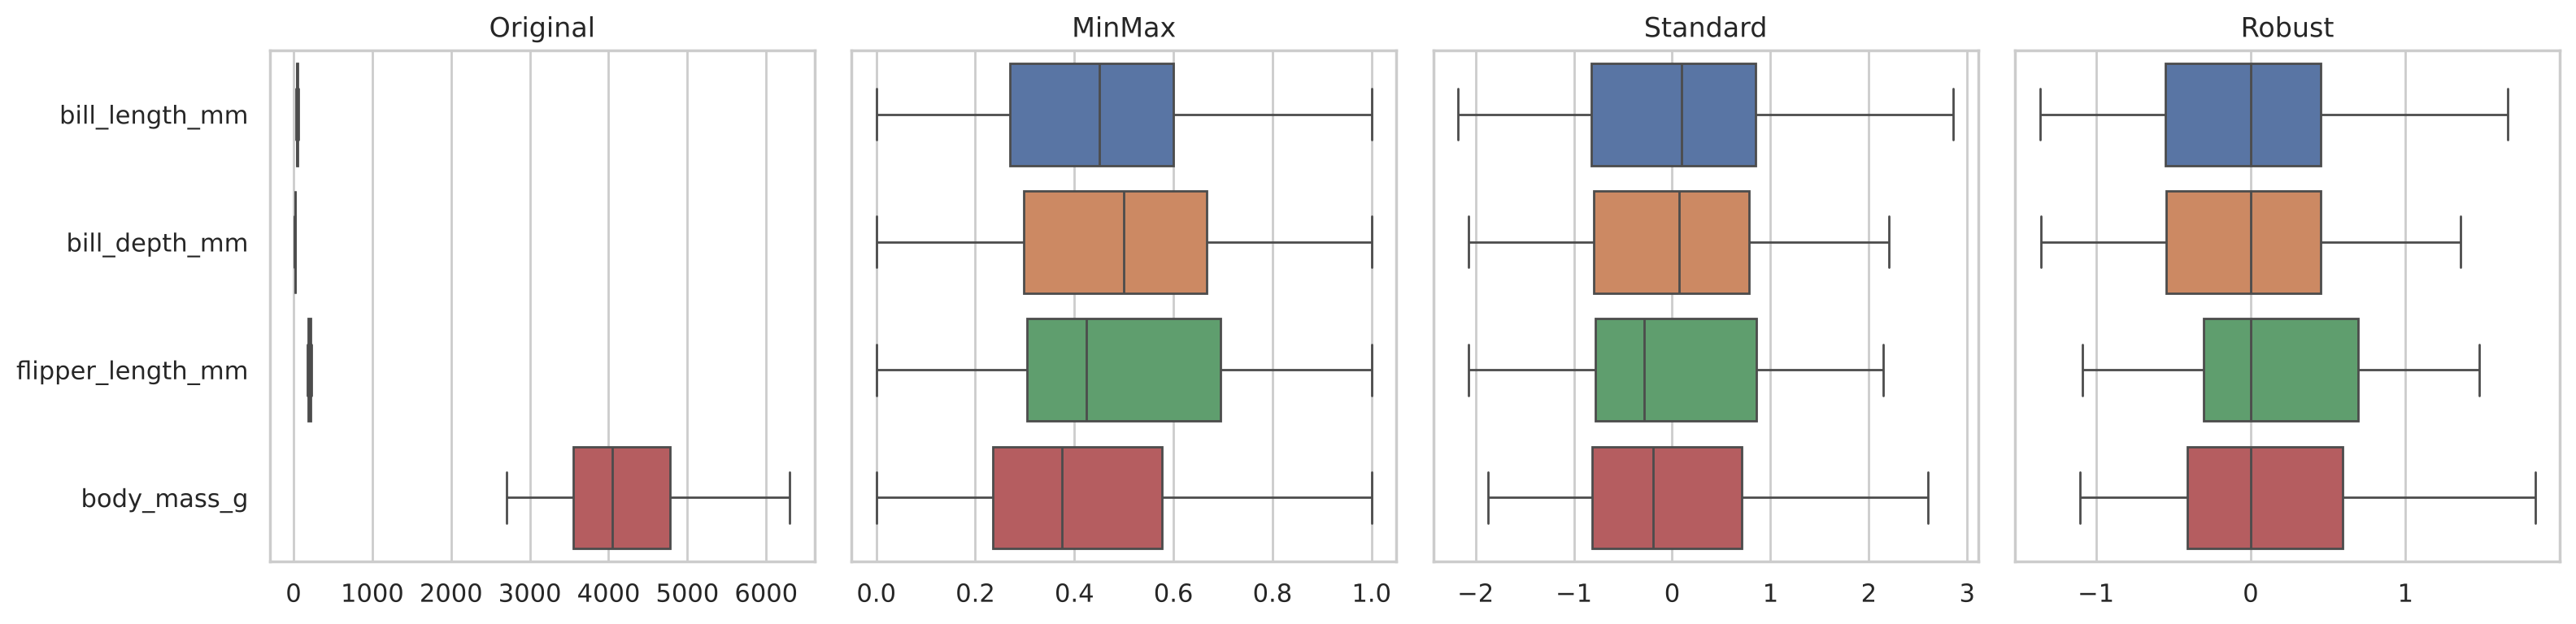

In [3]:
X = penguins[num_cols]
escaladores = {"Original": None, "MinMax": MinMaxScaler(), "Standard": StandardScaler(), "Robust": RobustScaler()}

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (nombre, esc) in zip(axes, escaladores.items()):
    Xt = X if esc is None else pd.DataFrame(esc.fit_transform(X), columns=num_cols)
    sns.boxplot(data=Xt, ax=ax, orient="h")
    ax.set_title(nombre)
    if nombre != "Original":
        ax.set_yticklabels([])
plt.tight_layout(); plt.show()

> **Lectura:** sin escalar, la masa "aplasta" a las otras variables. Con cualquier escalador las cuatro quedan comparables.

### ¿Y si hay valores extremos?
Agregamos 3 pingüinos imposibles de 15 kg y vemos cómo quedan los datos normales.

In [4]:
masa = penguins[["body_mass_g"]]
masa_con_extremos = pd.concat([masa, pd.DataFrame({"body_mass_g": [15000, 15500, 16000]})], ignore_index=True)

for nombre, esc in [("MinMax", MinMaxScaler()), ("Robust", RobustScaler())]:
    sin = esc.fit_transform(masa).ravel()
    con = esc.fit_transform(masa_con_extremos).ravel()[:-3]   # solo los pingüinos normales
    print(f"{nombre:7s} · sin extremos: {sin.min():.2f} a {sin.max():.2f}  |  con extremos: {con.min():.2f} a {con.max():.2f}")

MinMax  · sin extremos: 0.00 a 1.00  |  con extremos: 0.00 a 0.27
Robust  · sin extremos: -1.10 a 1.84  |  con extremos: -1.08 a 1.80


> Con MinMax, los pingüinos normales quedan apretados entre 0 y ~0,3 porque el máximo ahora es 16 000 g. Con RobustScaler los pingüinos normales quedan igual que antes: **si hay valores extremos, usa RobustScaler**.

## 2. Variables categóricas y rangos

Los modelos trabajan con números. ¿Qué hacemos con texto como `island` o `day`?

| Caso | Técnica | Ejemplo |
|---|---|---|
| Categorías **sin orden** | One-Hot: una columna 0/1 por categoría | `island`: Biscoe, Dream, Torgersen |
| Categorías **con orden** | Ordinal: un número que respeta el orden | `day`: Thur=0 < Fri=1 < Sat=2 < Sun=3 |
| Número → **grupos** | Discretizar en rangos | cuenta baja / media / alta |

In [5]:
ohe = OneHotEncoder(sparse_output=False)
onehot = pd.DataFrame(ohe.fit_transform(penguins[["island"]]), columns=ohe.get_feature_names_out())
pd.concat([penguins[["island"]], onehot], axis=1).head()

,island,island_Biscoe,island_Dream,island_Torgersen
0,Torgersen,0.0,0.0,1.0
1,Torgersen,0.0,0.0,1.0
2,Torgersen,0.0,0.0,1.0
3,Torgersen,0.0,0.0,1.0
4,Torgersen,0.0,0.0,1.0


In [6]:
ordinal = OrdinalEncoder(categories=[["Thur", "Fri", "Sat", "Sun"]])
tips["day_num"] = ordinal.fit_transform(tips[["day"]]).ravel()
tips[["day", "day_num"]].drop_duplicates().sort_values("day_num")

,day,day_num
77,Thur,0.0
90,Fri,1.0
19,Sat,2.0
0,Sun,3.0


              count    min    max
nivel_cuenta                     
baja             82   3.07  15.04
media            81  15.06  21.01
alta             81  21.16  50.81


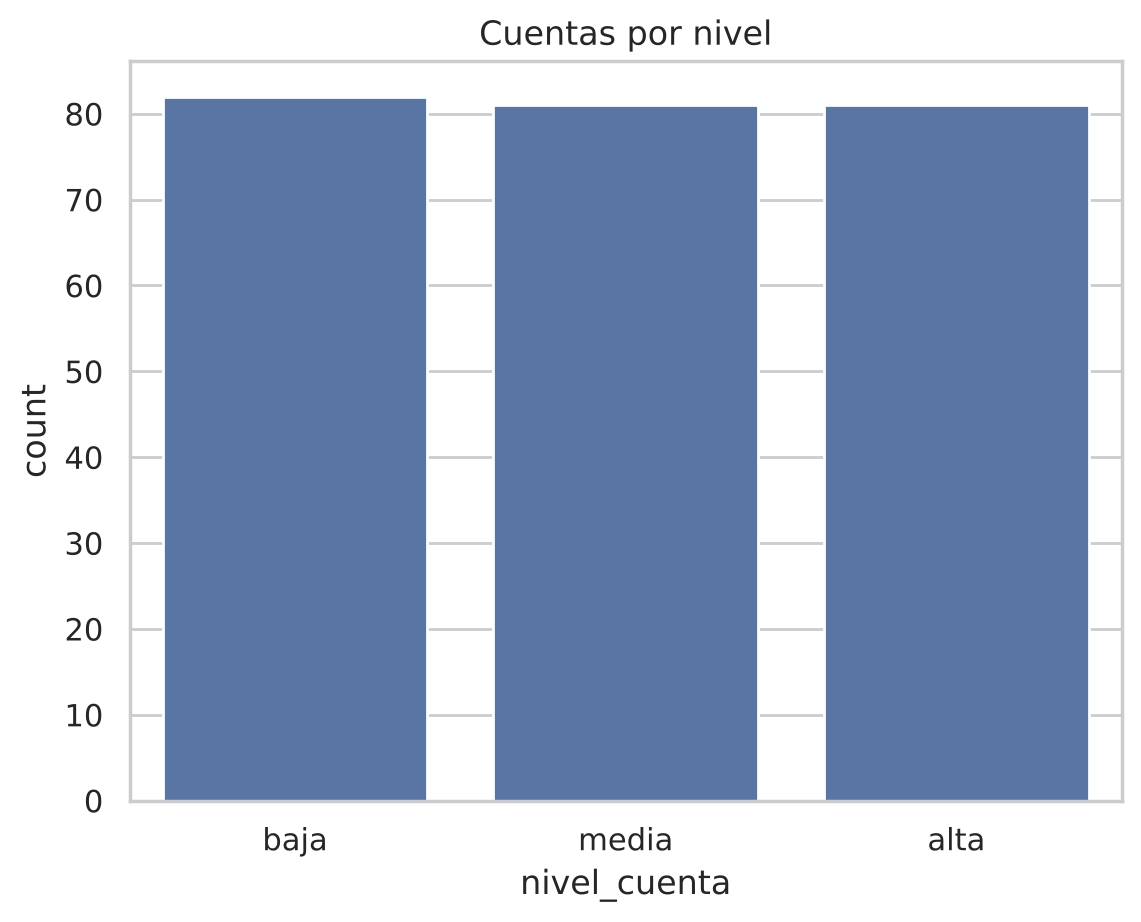

In [7]:
# Discretizar: 3 grupos con la misma cantidad de cuentas cada uno
tips["nivel_cuenta"] = pd.qcut(tips["total_bill"], q=3, labels=["baja", "media", "alta"])
print(tips.groupby("nivel_cuenta", observed=True)["total_bill"].agg(["count", "min", "max"]).round(2))
sns.countplot(tips, x="nivel_cuenta", color="#4C72B0"); plt.title("Cuentas por nivel"); plt.show()

> Discretizar simplifica (útil cuando el negocio piensa en rangos), pero **pierde detalle**: una cuenta de 16 y una de 24 USD quedan en el mismo grupo.

## 3. Reducción de dimensionalidad: PCA

**Idea:** tenemos 4 medidas de cada pingüino. ¿Podemos resumirlas en **2 números** sin perder mucha información? PCA busca las direcciones donde los datos varían más y crea nuevas variables (componentes) a partir de las originales.

Pasos: **1) escalar → 2) aplicar PCA → 3) ver cuánta información conserva cada componente → 4) graficar.**

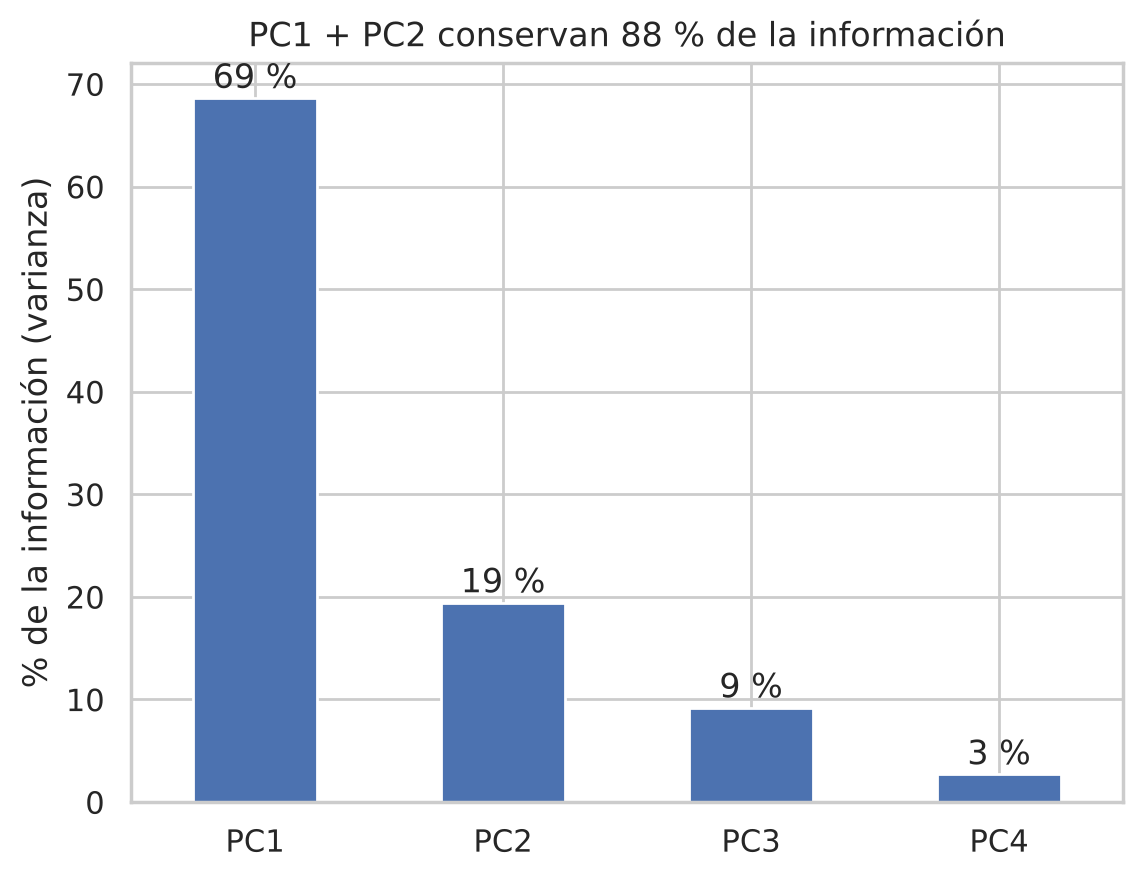

In [8]:
X_esc = StandardScaler().fit_transform(penguins[num_cols])   # 1) escalar (¡importante!)
pca = PCA(n_components=4).fit(X_esc)                          # 2) aplicar PCA

varianza = pd.Series(pca.explained_variance_ratio_ * 100, index=["PC1", "PC2", "PC3", "PC4"])
ax = varianza.plot.bar(color="#4C72B0", rot=0)
ax.set_ylabel("% de la información (varianza)")
ax.set_title(f"PC1 + PC2 conservan {varianza[:2].sum():.0f} % de la información")
for i, v in enumerate(varianza): ax.text(i, v + 1, f"{v:.0f} %", ha="center")
plt.show()

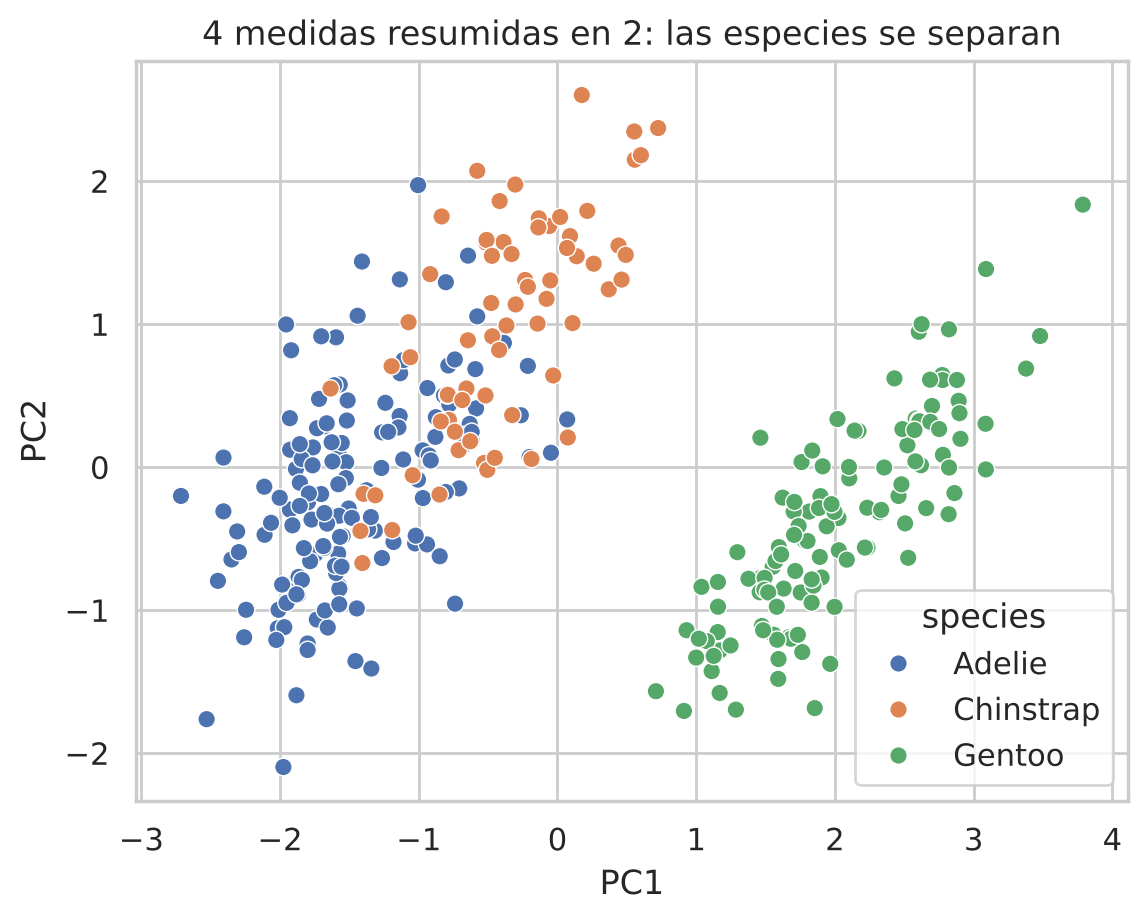

In [9]:
Z = pca.transform(X_esc)[:, :2]                               # 4) quedarnos con 2 componentes
ax = sns.scatterplot(x=Z[:, 0], y=Z[:, 1], hue=penguins["species"], s=40)
ax.set(xlabel="PC1", ylabel="PC2", title="4 medidas resumidas en 2: las especies se separan")
plt.show()

In [10]:
# ¿Qué representa PC1? Miramos cuánto pesa cada variable original
pd.DataFrame(pca.components_[:2].T, index=num_cols, columns=["PC1", "PC2"]).round(2)

,PC1,PC2
bill_length_mm,0.45,0.60
bill_depth_mm,-0.40,0.80
flipper_length_mm,0.58,0.01
body_mass_g,0.55,0.08


> **Lectura:** PC1 combina largo de aleta, masa y largo del pico → es como un "índice de tamaño". Con solo 2 números por pingüino vemos claramente las 3 especies.

### Ejemplo visual: 64 variables → 2
`digits` son imágenes de dígitos de 8×8 píxeles = 64 variables. Con PCA podemos dibujarlas en un plano.

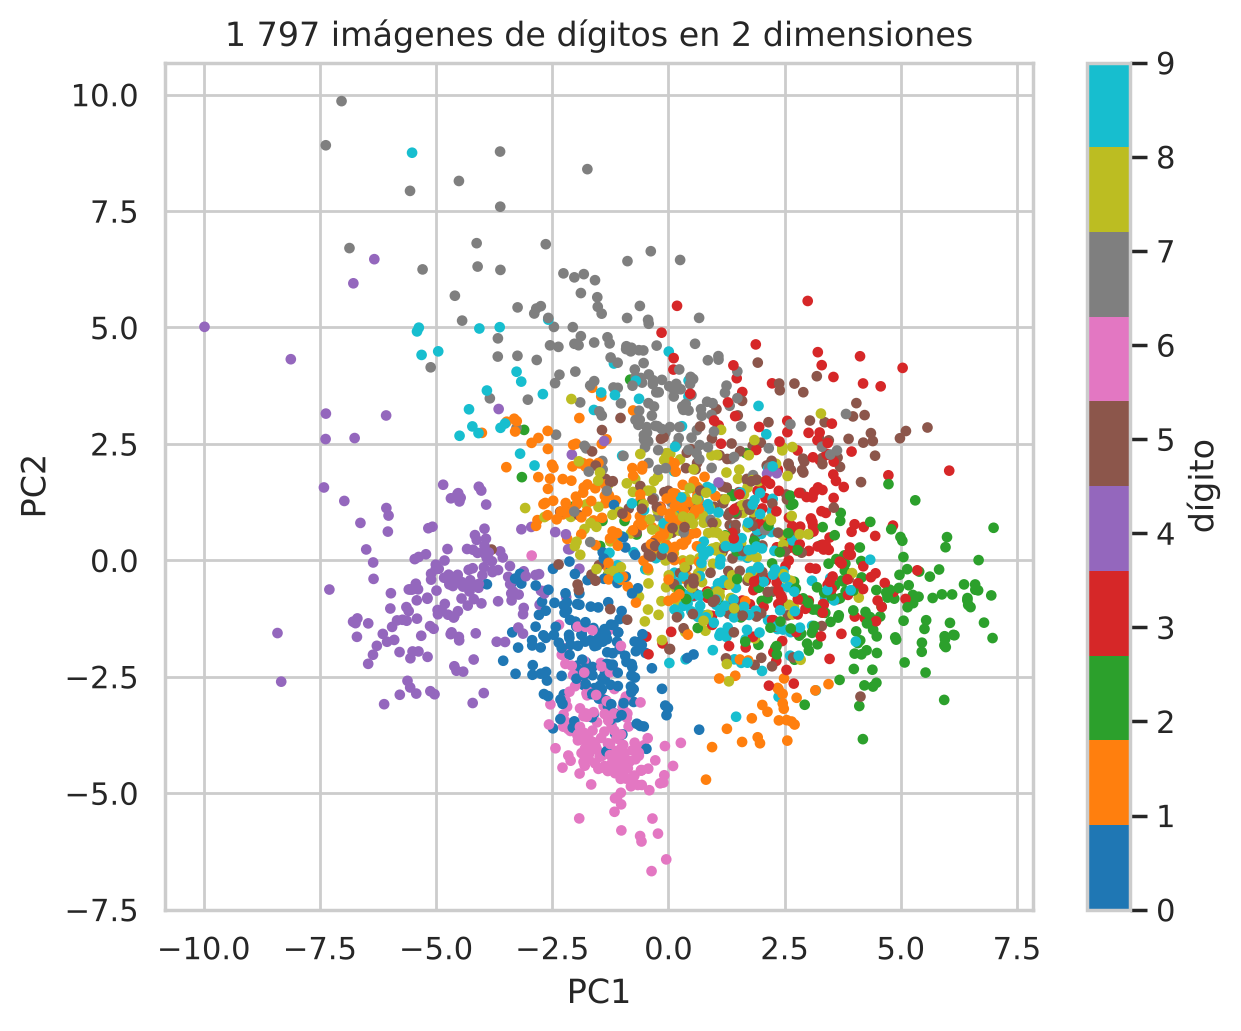

In [11]:
from sklearn.datasets import load_digits
digits = load_digits()
Zd = PCA(n_components=2).fit_transform(StandardScaler().fit_transform(digits.data))
plt.figure(figsize=(7, 5.5))
sc = plt.scatter(Zd[:, 0], Zd[:, 1], c=digits.target, cmap="tab10", s=8)
plt.colorbar(sc, ticks=range(10), label="dígito"); plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("1 797 imágenes de dígitos en 2 dimensiones"); plt.show()

## Resumen
1. **Escalar** cuando las variables tienen unidades muy distintas (y siempre antes de PCA). Con valores extremos → RobustScaler.
2. **One-Hot** para categorías sin orden, **ordinal** para categorías con orden.
3. **Discretizar** solo si se necesitan grupos; se pierde detalle.
4. **PCA** resume muchas variables en pocas; útil para visualizar.

➡️ **Ahora: `S2_taller_estudiantes.ipynb` (30 min).**